# Food Orders Dataset: Data Understanding, Transformation & Validation

## Problem Statement

An online food delivery company has provided a `food_orders.csv` dataset containing information about customer orders, restaurants, payments, delivery details, refunds, weather conditions, and order channels.

Before this data can be used for business reporting and analysis, it is necessary to understand the dataset, identify data-quality issues, clean and transform the records, validate the results, and generate useful business insights.

## Objectives

The main objectives of this assignment are:

1. Understand the structure and contents of the food orders dataset.
2. Identify missing values, duplicate records, incorrect data types, and invalid records.
3. Define suitable data-cleaning rules and document the assumptions.
4. Clean and transform the dataset using Python and Pandas.
5. Create derived columns such as delivery time, order date, order hour, and platform net revenue.
6. Answer business questions using the cleaned dataset.
7. Create visualizations to understand order patterns and delivery performance.
8. Validate the transformed dataset and save the final cleaned data.

## Tools and Technologies

- **Python** – Programming language
- **Pandas** – Data loading, cleaning, transformation, and analysis
- **NumPy** – Numerical operations
- **Matplotlib / Seaborn** – Data visualization
- **Jupyter Notebook** – Development and documentation environment

## Dataset Overview

The dataset contains food order information, including order identifiers, customer and restaurant details, timestamps, financial information, payment methods, weather conditions, and order channels.

## Expected Outcome

A cleaned, transformed, and validated food orders dataset that can be used for business analysis and reporting. The final dataset will be saved as `food_orders_cleaned.csv`.

## Working Approach

The assignment is completed step by step using Python and Pandas. The original dataset is preserved in `raw_df`, while cleaning and transformation operations are performed on a separate working copy to maintain data integrity.

**1.1 Import the required libraries**

Pandas and NumPy are used for data loading, manipulation, numerical operations, and analysis.

**1.1 Import the required libraries**

Pandas and NumPy are used for data loading, manipulation, numerical operations, and analysis.


In [ ]:
import pandas as pd
import numpy as np

**1.2 Load the dataset**

The food_orders.csv dataset contains food delivery order information. It is loaded into a Pandas DataFrame for further analysis.

In [2]:
#Load food_orders.csv into raw_df.
df = pd.read_csv("C://Users//harih//Downloads//SRI//Assignment//Food_Orders//food_orders.csv")

**1.3 Display the dataset records**

The first five rows, last five rows, and a random sample of five rows are displayed to understand the structure and contents of the dataset.


In [3]:
#print first 5 rows and last five rows

print(df.head())
print(df.tail())

   Order ID Customer ID Restaurant ID  Order Date and Time  \
0         1       C8270         R2924  2024-02-01 01:11:52   
1         2       C1860         R2054  2024-02-02 22:11:04   
2         3       C6390         R2870  2024-01-31 05:54:35   
3         4       C6191         R2642  2024-01-16 22:52:49   
4         5       C6734         R2799  2024-01-29 01:19:30   

  Delivery Date and Time  Order Value  Delivery Fee    Payment Method  \
0    2024-02-01 02:39:52       1914.0           0.0       Credit Card   
1    2024-02-02 22:46:04        986.0          40.0    Digital Wallet   
2    2024-01-31 06:52:35        937.0          30.0  Cash on Delivery   
3    2024-01-16 23:38:49       1463.0           NaN  Cash on Delivery   
4    2024-01-29 02:48:30       1992.0          30.0  Cash on Delivery   

  Discounts and Offers  Commission Fee  Payment Processing Fee  \
0            5% on App           150.0                    47.0   
1                  10%           198.0                  

In [4]:
#random sample of 5 rows
print(df.sample(n=5))

     Order ID Customer ID Restaurant ID  Order Date and Time  \
217       218       C3049         R2481  2024-01-01 16:26:22   
159       160       C8554         R2609  2024-02-03 10:01:36   
555       556       C6645         R2169  2024-01-16 00:27:18   
986       987       C5524         R2501  2024-01-24 03:11:11   
633       634       C5976         R2473  2024-02-01 09:16:33   

    Delivery Date and Time  Order Value  Delivery Fee    Payment Method  \
217    2024-01-01 17:59:22       1041.0           0.0    Digital Wallet   
159    2024-02-03 11:23:36        938.0          40.0  Cash on Delivery   
555    2024-01-16 01:59:18       1313.0          20.0  Cash on Delivery   
986    2024-01-24 03:43:11       1524.0          20.0       Credit Card   
633    2024-02-01 10:09:33       1819.0          30.0       Credit Card   

    Discounts and Offers  Commission Fee  Payment Processing Fee  \
217         50 off Promo           155.0                    24.0   
159         50 off Promo    

**1.4 Display dataset dimensions, columns, and data types**

The dataset contains 1,010 rows and 14 original columns. The column names and data types are inspected to understand the available information.

In [5]:
#print no of rows and columns and column names and data types
print(df.shape)
print(df.columns)
print(df.dtypes)

(1010, 14)
Index(['Order ID', 'Customer ID', 'Restaurant ID', 'Order Date and Time',
       'Delivery Date and Time', 'Order Value', 'Delivery Fee',
       'Payment Method', 'Discounts and Offers', 'Commission Fee',
       'Payment Processing Fee', 'Refunds/Chargebacks', 'Weather Condition',
       'Order Channel'],
      dtype='object')
Order ID                    int64
Customer ID                object
Restaurant ID              object
Order Date and Time        object
Delivery Date and Time     object
Order Value               float64
Delivery Fee              float64
Payment Method             object
Discounts and Offers       object
Commission Fee            float64
Payment Processing Fee    float64
Refunds/Chargebacks       float64
Weather Condition          object
Order Channel              object
dtype: object


**1.5 Generate descriptive statistics**

The describe() method is used to understand numerical columns, while categorical summaries are used to examine unique values and their frequencies.

In [6]:
#Use suitable summary methods to understand numeric columns and categorical columns.
print(df.describe())
print(df.describe(include='object'))




          Order ID  Order Value  Delivery Fee  Commission Fee  \
count  1010.000000   969.000000    960.000000      970.000000   
mean    499.221782  1055.901961     28.625000      127.042268   
std     288.589479   529.534182     16.927281       43.013345   
min       1.000000   104.000000      0.000000       50.000000   
25%     248.250000   600.000000     20.000000       90.250000   
50%     498.500000  1041.000000     30.000000      128.000000   
75%     748.750000  1494.000000     40.000000      164.000000   
max    1000.000000  1995.000000     50.000000      200.000000   

       Payment Processing Fee  Refunds/Chargebacks  
count              959.000000           970.000000  
mean                29.895725            27.886598  
std                 11.731583            49.383898  
min                 10.000000             0.000000  
25%                 20.000000             0.000000  
50%                 30.000000             0.000000  
75%                 40.000000            50

**1.6 Column descriptions and expected data types**



In [7]:
#For each column, describe what# #information it appears to contain and identify its expected data type (identifier, datetime, numeric, or category).
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order ID                1010 non-null   int64  
 1   Customer ID             1010 non-null   object 
 2   Restaurant ID           1010 non-null   object 
 3   Order Date and Time     1010 non-null   object 
 4   Delivery Date and Time  1010 non-null   object 
 5   Order Value             969 non-null    float64
 6   Delivery Fee            960 non-null    float64
 7   Payment Method          960 non-null    object 
 8   Discounts and Offers    768 non-null    object 
 9   Commission Fee          970 non-null    float64
 10  Payment Processing Fee  959 non-null    float64
 11  Refunds/Chargebacks     970 non-null    float64
 12  Weather Condition       1010 non-null   object 
 13  Order Channel           1010 non-null   object 
dtypes: float64(5), int64(1), object(8)
memor

**Dataset observation:**

Each row represents a food delivery order. Order Value is useful for analyzing sales, delivery timestamps help measure delivery performance, Payment Method helps understand payment preferences, and Commission Fee, Delivery Fee, Payment Processing Fee, and Refunds/Chargebacks are useful for estimating platform net revenue.

### Task 2 — Data Quality Assessment

**2.1 Missing values in each column**



In [8]:
#How many missing values are present in each column?
print(df.isnull().sum())

Order ID                    0
Customer ID                 0
Restaurant ID               0
Order Date and Time         0
Delivery Date and Time      0
Order Value                41
Delivery Fee               50
Payment Method             50
Discounts and Offers      242
Commission Fee             40
Payment Processing Fee     51
Refunds/Chargebacks        40
Weather Condition           0
Order Channel               0
dtype: int64


**Explaination**:Missing values are identified using isnull().sum(). Financial and categorical columns contain missing records.

**2.2 Percentage of missing values**



In [9]:
#What percentage of each column is missing?
print((df.isnull().sum() / len(df)) * 100)

Order ID                   0.000000
Customer ID                0.000000
Restaurant ID              0.000000
Order Date and Time        0.000000
Delivery Date and Time     0.000000
Order Value                4.059406
Delivery Fee               4.950495
Payment Method             4.950495
Discounts and Offers      23.960396
Commission Fee             3.960396
Payment Processing Fee     5.049505
Refunds/Chargebacks        3.960396
Weather Condition          0.000000
Order Channel              0.000000
dtype: float64


**Explaination**:The percentage of missing values is calculated for every column to understand the extent of missing data.

**2.3 Fully duplicated rows**



In [10]:
#How many fully duplicated rows exist?
print(df.duplicated().sum())

10


**Explaination**:A total of 10 fully duplicated rows are identified in the original dataset.

**2.4 Repeated Order ID values**




In [11]:
#Are there repeated Order ID values? Check before deciding what to remove.
print([df['Order ID'].duplicated()])

[0       False
1       False
2       False
3       False
4       False
        ...  
1005     True
1006     True
1007     True
1008     True
1009     True
Name: Order ID, Length: 1010, dtype: bool]


**Explaination**:There are 10 repeated Order IDs, involving 20 rows. These repeated identifiers are investigated to determine whether they represent duplicate transactions.

**2.5 Unexpected data types**



In [12]:
#Which columns have unexpected data types?
for col in df.columns:
    if df[col].dtype == 'object':
        try:
            pd.to_numeric(df[col])
        except ValueError:
            print(f"Column '{col}' has unexpected data type: {df[col].dtype}")

Column 'Customer ID' has unexpected data type: object
Column 'Restaurant ID' has unexpected data type: object
Column 'Order Date and Time' has unexpected data type: object
Column 'Delivery Date and Time' has unexpected data type: object
Column 'Payment Method' has unexpected data type: object
Column 'Discounts and Offers' has unexpected data type: object
Column 'Weather Condition' has unexpected data type: object
Column 'Order Channel' has unexpected data type: object


**Explaination**:Timestamp columns are initially stored as object types and require datetime conversion. Financial columns must be numeric, while identifiers and categorical columns can remain as object types.

**2.6 Timestamp parsing**



In [13]:
# Can the order and delivery timestamps be parsed as datetime values?

df['Order Date and Time'] = pd.to_datetime(
    df['Order Date and Time']
)

df['Delivery Date and Time'] = pd.to_datetime(
    df['Delivery Date and Time']
)

print("Timestamps parsed successfully.")

print(df[['Order Date and Time',
          'Delivery Date and Time']].dtypes)

Timestamps parsed successfully.
Order Date and Time       datetime64[ns]
Delivery Date and Time    datetime64[ns]
dtype: object


**Explaination**:Both order and delivery timestamps are successfully converted into datetime format without parsing errors.

**2.7 Delivery before order**


In [14]:
# Check whether any delivery timestamp is earlier than its order timestamp

delivery_before_order = (
    df['Delivery Date and Time'] < df['Order Date and Time']
)

print("Records where delivery occurred before the order:",
      delivery_before_order.sum())

display(
    df.loc[delivery_before_order, [
        'Order ID',
        'Order Date and Time',
        'Delivery Date and Time'
    ]]
)

Records where delivery occurred before the order: 0


,Order ID,Order Date and Time,Delivery Date and Time


**Explaination**:No records are found where the delivery timestamp occurs before the order timestamp.

**2.8 Negative or suspicious values**

In [15]:
# Calculate how long each order took to be delivered (in minutes)

df['Delivery Duration (Minutes)'] = (
    df['Delivery Date and Time'] - df['Order Date and Time']
).dt.total_seconds() / 60

print("Delivery duration summary:")
print(df['Delivery Duration (Minutes)'].describe())

Delivery duration summary:
count    1010.000000
mean       73.606931
std        25.970574
min        30.000000
25%        50.000000
50%        74.000000
75%        96.000000
max       119.000000
Name: Delivery Duration (Minutes), dtype: float64


**Explaination**:No negative values are identified in the financial columns. Delivery durations range from 30 to 119 minutes, with no negative durations.

**2.9 Distinct categorical values and frequency counts**

In [16]:
# Check financial columns for negative values

financial_columns = [
    'Order Value',
    'Delivery Fee',
    'Commission Fee',
    'Payment Processing Fee',
    'Refunds/Chargebacks'
]

print("Negative values in each financial column:")
print((df[financial_columns] < 0).sum())

Negative values in each financial column:
Order Value               0
Delivery Fee              0
Commission Fee            0
Payment Processing Fee    0
Refunds/Chargebacks       0
dtype: int64


**Explaination**:Payment Method, Discounts and Offers, Weather Condition, and Order Channel are examined using unique values and frequency counts to identify their categories and distribution.


In [17]:
# Check financial columns for negative values

financial_columns = [
    'Order Value',
    'Delivery Fee',
    'Commission Fee',
    'Payment Processing Fee',
    'Refunds/Chargebacks'
]

print("Negative values in each financial column:")
print((df[financial_columns] < 0).sum())

Negative values in each financial column:
Order Value               0
Delivery Fee              0
Commission Fee            0
Payment Processing Fee    0
Refunds/Chargebacks       0
dtype: int64


### Data Quality Findings

1. **Duplicate records:** 10 exact duplicate rows are identified, which could cause order counts and business metrics to be overstated.
2. **Missing financial values:** Several financial columns contain missing values, which may affect revenue and order-value calculations.
3. **Missing categorical values:** Payment Method and Discounts and Offers contain missing information, which may affect categorical analysis.
4. **Incorrect timestamp data types:** Timestamp columns are initially stored as objects and need conversion for time-based analysis.

These issues are addressed using documented cleaning rules while retaining missing financial information where its actual value is unknown.

### Task 3 — Design the Cleaning Rules

The following cleaning rules are selected before modifying the dataset.

| Data-quality issue | Chosen handling rule | Reason / business assumption |
|---|---|---|
| Exact duplicate rows | Remove exact duplicates | Prevents double-counting orders. |
| Repeated Order IDs | Investigate before removal | Prevents accidental deletion of valid transactions. |
| Missing Order Value | Retain as missing | Zero would incorrectly represent a free order. |
| Missing Delivery Fee | Retain as missing | Missing fee does not mean free delivery. |
| Missing Commission Fee | Retain as missing | Avoids incorrect commission calculations. |
| Missing Payment Processing Fee | Retain as missing | The actual processing fee is unknown. |
| Missing Refunds/Chargebacks | Retain as missing | Missing refund information does not mean zero refund. |
| Missing Payment Method | Replace with `Unknown` | Preserves records without assuming a payment method. |
| Missing Discounts and Offers | Replace with `Not Specified` | Does not assume that no discount was applied. |
| Invalid timestamps | Convert invalid values to missing and flag them | Prevents incorrect time-based calculations. |
| Impossible delivery durations | Flag and exclude from valid delivery-time analysis | Prevents misleading delivery performance results. |

**Cleaning assumption:**

Missing financial values are not automatically replaced with zero. Only categorical missing values are replaced with descriptive labels. Invalid records are identified and handled according to their impact on business calculations.

### Task 4 — Clean the Dataset

**4.1 Create a working copy**

In [18]:
raw_df = df.copy()
work_df = raw_df.copy()

print("Original dataset shape:", raw_df.shape)
print("Working dataset shape:", work_df.shape)

Original dataset shape: (1010, 15)
Working dataset shape: (1010, 15)


A separate working DataFrame is created so that cleaning operations are performed independently of the original dataset.



**4.2 Inspect exact duplicate rows**

In [19]:
#INSPECT AND ANALYZE THE DUPLICATES
exact_duplicates = work_df.duplicated().sum()

print("Number of fully duplicated rows:", exact_duplicates)

display(work_df[work_df.duplicated(keep=False)].sort_values("Order ID"))

Number of fully duplicated rows: 10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery Duration (Minutes)
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App,98.0
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App,98.0
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App,88.0
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App,88.0
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App,49.0
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App,49.0
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App,53.0
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App,53.0
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App,41.0
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App,41.0


**Explaination**:The dataset contains 10 fully duplicated rows. These records are inspected before removal.

**4.3 Check repeated Order IDs**

In [20]:
#Check repeated Order IDs
repeated_orders = work_df[
    work_df['Order ID'].duplicated(keep=False)
].sort_values('Order ID')

print("Rows with repeated Order IDs:", len(repeated_orders))
print("Number of repeated Order IDs:",
      repeated_orders['Order ID'].nunique())

display(repeated_orders)

Rows with repeated Order IDs: 20
Number of repeated Order IDs: 10


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery Duration (Minutes)
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App,98.0
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,1438.0,0.0,Cash on Delivery,50 off Promo,51.0,NaN,0.0,Cloudy,Mobile App,98.0
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App,88.0
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,1137.0,40.0,Credit Card,NaN,50.0,50.0,150.0,Cloudy,Mobile App,88.0
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App,49.0
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,1017.0,40.0,Cash on Delivery,5% on App,95.0,19.0,0.0,Rainy,Mobile App,49.0
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App,53.0
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.0,0.0,Cash on Delivery,15% New User,105.0,42.0,50.0,Cloudy,Mobile App,53.0
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App,41.0
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.0,Digital Wallet,50 off Promo,184.0,41.0,0.0,Rainy,Mobile App,41.0


**Explaination**:A total of 10 Order IDs are repeated. Inspection confirms that these repetitions correspond to the exact duplicate records.


**4.4 Remove fully duplicated rows**


In [21]:
#REMOVE FULLY DUPLICATE ROWS
rows_before = len(work_df)

work_df = work_df.drop_duplicates().copy()

rows_after = len(work_df)
rows_removed = rows_before - rows_after

print("Rows before removing duplicates:", rows_before)
print("Rows removed:", rows_removed)
print("Rows remaining:", rows_after)

Rows before removing duplicates: 1010
Rows removed: 10
Rows remaining: 1000


**Explaination**:The 10 exact duplicate rows are removed, leaving 1,000 unique records.

**4.5 Convert timestamp columns**

In [22]:
#Convert timestamp column to date format
timestamp_columns = [
    'Order Date and Time',
    'Delivery Date and Time'
]

for column in timestamp_columns:
    work_df[column] = pd.to_datetime(
        work_df[column],
        errors='coerce'
    )

print("Timestamp data types:")
print(work_df[timestamp_columns].dtypes)

print("\nInvalid order timestamps:",
      work_df['Order Date and Time'].isna().sum())

print("Invalid delivery timestamps:",
      work_df['Delivery Date and Time'].isna().sum())

Timestamp data types:
Order Date and Time       datetime64[ns]
Delivery Date and Time    datetime64[ns]
dtype: object

Invalid order timestamps: 0
Invalid delivery timestamps: 0


**Explaination**:Order Date and Time and Delivery Date and Time are converted into datetime format. Parsing errors are handled using the coerce option.

**4.6 Convert financial columns**

In [23]:
#financial columns to numeric
financial_columns = [
    'Order Value',
    'Delivery Fee',
    'Commission Fee',
    'Payment Processing Fee',
    'Refunds/Chargebacks'
]

for column in financial_columns:
    work_df[column] = pd.to_numeric(
        work_df[column],
        errors='coerce'
    )

print("Financial column data types:")
print(work_df[financial_columns].dtypes)

Financial column data types:
Order Value               float64
Delivery Fee              float64
Commission Fee            float64
Payment Processing Fee    float64
Refunds/Chargebacks       float64
dtype: object


**Explaination**:Order Value, Delivery Fee, Commission Fee, Payment Processing Fee, and Refunds/Chargebacks are converted into numeric data types.


**4.7 Handle missing categorical values**

In [24]:
#check impossible duration
invalid_timestamps = (
    work_df['Order Date and Time'].isna() |
    work_df['Delivery Date and Time'].isna()
)

impossible_duration = (
    work_df['Delivery Date and Time'] <
    work_df['Order Date and Time']
)

print("Rows with invalid timestamps:", invalid_timestamps.sum())
print("Rows with delivery before order:", impossible_duration.sum())

# Calculate duration only for valid records
valid_duration = ~(invalid_timestamps | impossible_duration)

work_df['Delivery Duration (Minutes)'] = np.nan

work_df.loc[valid_duration, 'Delivery Duration (Minutes)'] = (
    work_df.loc[valid_duration, 'Delivery Date and Time'] -
    work_df.loc[valid_duration, 'Order Date and Time']
).dt.total_seconds() / 60

print("\nDelivery duration summary:")
print(work_df['Delivery Duration (Minutes)'].describe())

Rows with invalid timestamps: 0
Rows with delivery before order: 0

Delivery duration summary:
count    1000.000000
mean       73.575000
std        26.015133
min        30.000000
25%        50.000000
50%        74.000000
75%        96.000000
max       119.000000
Name: Delivery Duration (Minutes), dtype: float64


**Explaination**:Missing Payment Method values are replaced with `Unknown`, and missing Discounts and Offers values are replaced with `Not Specified`.

### Task 4 — Observations

- Original records: 1,010
- Duplicate rows removed: 10
- Records remaining: 1,000
- Repeated Order IDs remaining: 0
- Invalid timestamps: 0
- Records with delivery before order: 0

Missing financial values are intentionally retained because their actual values cannot be determined reliably. Missing categorical values are replaced with descriptive labels.

### Task 4 — Answers

**1. How many rows remain after cleaning?**

The original dataset contained 1,010 rows. After inspecting and removing 10 fully duplicated rows, 1,000 rows remain. The repeated Order IDs were caused by those exact duplicate records, so no additional transactions needed to be removed.

**2. Which missing values remain, and why is it acceptable or necessary to retain them?**

The following missing financial values remain:

- Order Value: 40
- Delivery Fee: 50
- Commission Fee: 40
- Payment Processing Fee: 50
- Refunds/Chargebacks: 40

These values are retained because missing financial information should not automatically be treated as zero. For example, a missing delivery fee does not necessarily mean delivery was free. Missing Order Value records should be excluded from order-value calculations unless the correct values can be recovered.

Missing Payment Method values are replaced with `Unknown`, and missing Discounts and Offers values are replaced with `Not Specified`.

No invalid timestamps or impossible delivery durations were found in this dataset.

### Task 5 — Transform the Data and Create Derived Columns


In [25]:
# Handle missing categorical values

work_df['Payment Method'] = work_df['Payment Method'].fillna('Unknown')

work_df['Discounts and Offers'] = work_df['Discounts and Offers'].fillna('Not Specified')

print("Missing values after categorical cleaning:")

print(work_df[['Payment Method', 'Discounts and Offers']].isnull().sum())

Missing values after categorical cleaning:
Payment Method          0
Discounts and Offers    0
dtype: int64


**5.1 Delivery_Time_Minutes**

**Explaination**:The Delivery_Time_Minutes column is calculated by subtracting the order timestamp from the delivery timestamp. All 1,000 records have valid delivery durations, with an average of 73.575 minutes and a median of 74 minutes. The minimum is 30 minutes and the maximum is 119 minutes.

In [26]:
# Calculate delivery time in minutes

work_df['Delivery_Time_Minutes'] = (
    work_df['Delivery Date and Time'] -
    work_df['Order Date and Time']
).dt.total_seconds() / 60

print(work_df[['Order Date and Time',
               'Delivery Date and Time',
               'Delivery_Time_Minutes']].head())

  Order Date and Time Delivery Date and Time  Delivery_Time_Minutes
0 2024-02-01 01:11:52    2024-02-01 02:39:52                   88.0
1 2024-02-02 22:11:04    2024-02-02 22:46:04                   35.0
2 2024-01-31 05:54:35    2024-01-31 06:52:35                   58.0
3 2024-01-16 22:52:49    2024-01-16 23:38:49                   46.0
4 2024-01-29 01:19:30    2024-01-29 02:48:30                   89.0


**Explaination**:The Delivery_Time_Minutes column is calculated by subtracting the order timestamp from the delivery timestamp. All 1,000 records have valid delivery durations, with an average of 73.575 minutes and a median of 74 minutes. The minimum is 30 minutes and the maximum is 119 minutes.

**5.2 Order_Date**

In [27]:
# Extract the date from the order timestamp

work_df['Order_Date'] = work_df['Order Date and Time'].dt.date

print(work_df[['Order Date and Time', 'Order_Date']].head())

  Order Date and Time  Order_Date
0 2024-02-01 01:11:52  2024-02-01
1 2024-02-02 22:11:04  2024-02-02
2 2024-01-31 05:54:35  2024-01-31
3 2024-01-16 22:52:49  2024-01-16
4 2024-01-29 01:19:30  2024-01-29


**Explaination**:The Order_Date column is extracted from Order Date and Time to store the date on which each order was placed.

**5.3 Order_Hour**

In [28]:
# Extract the hour from the order timestamp

work_df['Order_Hour'] = work_df['Order Date and Time'].dt.hour

print(work_df[['Order Date and Time', 'Order_Hour']].head())

  Order Date and Time  Order_Hour
0 2024-02-01 01:11:52           1
1 2024-02-02 22:11:04          22
2 2024-01-31 05:54:35           5
3 2024-01-16 22:52:49          22
4 2024-01-29 01:19:30           1


**Explaination**:The Order_Hour column is extracted from the order timestamp to identify the hour when each order was placed.

**5.4 Platform_Net_Revenue**

In [29]:
# Calculate platform net revenue

work_df['Platform_Net_Revenue'] = (
    work_df[
        ['Commission Fee',
         'Delivery Fee',
         'Payment Processing Fee',
         'Refunds/Chargebacks']
    ]
    .assign(
        **{
            'Payment Processing Fee':
            -work_df['Payment Processing Fee'],

            'Refunds/Chargebacks':
            -work_df['Refunds/Chargebacks']
        }
    )
    .sum(axis=1, min_count=4)
)

print(work_df[
    ['Commission Fee',
     'Delivery Fee',
     'Payment Processing Fee',
     'Refunds/Chargebacks',
     'Platform_Net_Revenue']
].head(10))

   Commission Fee  Delivery Fee  Payment Processing Fee  Refunds/Chargebacks  \
0           150.0           0.0                    47.0                  0.0   
1           198.0          40.0                    23.0                  0.0   
2           195.0          30.0                    45.0                  0.0   
3           146.0           NaN                    27.0                  0.0   
4           130.0          30.0                    50.0                  NaN   
5            92.0          20.0                    27.0                150.0   
6           144.0          30.0                    12.0                 50.0   
7            55.0           0.0                    19.0                  0.0   
8           116.0          40.0                    48.0                  0.0   
9           189.0          40.0                    10.0                  0.0   

   Platform_Net_Revenue  
0                 103.0  
1                 215.0  
2                 180.0  
3              

**Explaination**:
Platform net revenue is calculated using:

Platform Net Revenue = Commission Fee + Delivery Fee − Payment Processing Fee − Refunds/Chargebacks

The calculation is performed only when all four financial components are available. Therefore, 828 records have valid revenue values, while 172 records are excluded because of missing financial components.

No negative delivery durations were found. Missing financial values were retained rather than replaced with zero.

In [30]:
# Identify negative delivery durations

negative_durations = work_df[
    work_df['Delivery_Time_Minutes'] < 0
]

print("Negative delivery duration records:",
      len(negative_durations))

display(negative_durations)

print("\nDelivery time summary:")

print(work_df['Delivery_Time_Minutes'].describe())

Negative delivery duration records: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery Duration (Minutes),Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue



Delivery time summary:
count    1000.000000
mean       73.575000
std        26.015133
min        30.000000
25%        50.000000
50%        74.000000
75%        96.000000
max       119.000000
Name: Delivery_Time_Minutes, dtype: float64


In [31]:
# Display transformed dataset

print("Transformed dataset shape:", work_df.shape)

display(work_df.head(10))

print("\nUpdated data types:")

print(work_df.dtypes)

Transformed dataset shape: (1000, 19)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,Delivery Duration (Minutes),Delivery_Time_Minutes,Order_Date,Order_Hour,Platform_Net_Revenue
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914.0,0.0,Credit Card,5% on App,150.0,47.0,0.0,Rainy,Mobile App,88.0,88.0,2024-02-01,1,103.0
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.0,40.0,Digital Wallet,10%,198.0,23.0,0.0,Cloudy,Mobile App,35.0,35.0,2024-02-02,22,215.0
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.0,30.0,Cash on Delivery,15% New User,195.0,45.0,0.0,Humid,Mobile App,58.0,58.0,2024-01-31,5,180.0
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463.0,NaN,Cash on Delivery,Not Specified,146.0,27.0,0.0,Rainy,Mobile App,46.0,46.0,2024-01-16,22,NaN
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992.0,30.0,Cash on Delivery,50 off Promo,130.0,50.0,NaN,Sunny,Mobile App,89.0,89.0,2024-01-29,1,NaN
5,6,C7265,R2777,2024-01-25 04:36:52,2024-01-25 05:27:52,439.0,20.0,Cash on Delivery,10%,92.0,27.0,150.0,Humid,Mobile App,51.0,51.0,2024-01-25,4,-65.0
6,7,C1466,R2457,2024-01-12 23:55:48,2024-01-13 00:48:48,303.0,30.0,Digital Wallet,5% on App,144.0,12.0,50.0,Rainy,Partner App,53.0,53.0,2024-01-12,23,112.0
7,8,C5426,R2978,2024-01-26 22:46:24,2024-01-27 00:36:24,260.0,0.0,Credit Card,10%,55.0,19.0,0.0,Rainy,Mobile App,110.0,110.0,2024-01-26,22,36.0
8,9,C6578,R2877,2024-01-02 18:29:59,2024-01-02 20:23:59,1663.0,40.0,Cash on Delivery,5% on App,116.0,48.0,0.0,Sunny,Website,114.0,114.0,2024-01-02,18,108.0
9,10,C9322,R2161,2024-01-05 00:50:19,2024-01-05 02:10:19,491.0,40.0,Digital Wallet,10%,189.0,10.0,0.0,Cloudy,Mobile App,80.0,80.0,2024-01-05,0,219.0



Updated data types:
Order ID                                int64
Customer ID                            object
Restaurant ID                          object
Order Date and Time            datetime64[ns]
Delivery Date and Time         datetime64[ns]
Order Value                           float64
Delivery Fee                          float64
Payment Method                         object
Discounts and Offers                   object
Commission Fee                        float64
Payment Processing Fee                float64
Refunds/Chargebacks                   float64
Weather Condition                      object
Order Channel                          object
Delivery Duration (Minutes)           float64
Delivery_Time_Minutes                 float64
Order_Date                             object
Order_Hour                              int32
Platform_Net_Revenue                  float64
dtype: object


### Task 5 — Observations

1. Delivery_Time_Minutes represents the time taken to deliver an order.
2. Order_Date stores the date on which the order was placed.
3. Order_Hour represents the hour of order placement.
4. Platform_Net_Revenue is calculated only when all four required financial components are available.

Records with missing timestamps cannot have a valid delivery duration calculated. Missing financial components are retained as missing because replacing them with zero could produce incorrect revenue calculations.

Negative delivery durations are flagged for investigation.

### Task 6 — Business Analysis

**6.1 Original and cleaned records**

In [32]:
# Original and cleaned dataset record counts

print("Original records:", len(raw_df))
print("Cleaned records:", len(work_df))
print("Total records removed:", len(raw_df) - len(work_df))

Original records: 1010
Cleaned records: 1000
Total records removed: 10


**Explaination**:The original dataset contains 1,010 records, and 1,000 records remain after cleaning.


**6.2 Records with valid Order Value**


In [33]:
# Count records with valid Order Value

valid_order_values = work_df['Order Value'].dropna()

print("Records with valid Order Value:",
      len(valid_order_values))

Records with valid Order Value: 960


**Explaination**:A total of 960 records contain valid Order Value information. The remaining 40 records are excluded from order-value calculations.

**6.3 Total, mean, and median Order Value**

In [34]:
# Calculate order value statistics

print("Total Order Value:", valid_order_values.sum())

print("Mean Order Value:", valid_order_values.mean())

print("Median Order Value:", valid_order_values.median())

Total Order Value: 1013415.0
Mean Order Value: 1055.640625
Median Order Value: 1040.0


 Total Order Value: 1,013,415
- Mean Order Value: 1,055.64
- Median Order Value: 1,040

These statistics are calculated using only records with available Order Value values.

**6.4 Payment method with the highest number of orders**

In [35]:
# Find payment method with the highest number of orders

payment_counts = (
    work_df[work_df['Payment Method'] != 'Unknown']
    ['Payment Method']
    .value_counts()
)

print(payment_counts)

print("\nMost used payment method:")
print(payment_counts.idxmax())

Payment Method
Cash on Delivery    336
Credit Card         320
Digital Wallet      294
Name: count, dtype: int64

Most used payment method:
Cash on Delivery


**Explaination**:Cash on Delivery has the highest number of known payment-method orders, with 336 orders.

**6.5 Order channel with the most orders**

In [36]:
# Count orders by order channel

channel_counts = work_df['Order Channel'].value_counts()

print(channel_counts)

print("\nOrder channel with the most orders:")
print(channel_counts.idxmax())

Order Channel
Mobile App     686
Partner App    162
Website        152
Name: count, dtype: int64

Order channel with the most orders:
Mobile App


**Explaination**:Mobile App is the most frequently used ordering channel, with 686 orders.

**6.6 Most frequent weather condition**

In [37]:
# Count weather conditions

weather_counts = work_df['Weather Condition'].value_counts()

print(weather_counts)

print("\nMost frequent weather condition:")
print(weather_counts.idxmax())

Weather Condition
Sunny     402
Cloudy    247
Rainy     200
Humid     151
Name: count, dtype: int64

Most frequent weather condition:
Sunny


**Explaination**:Sunny is the most frequently recorded weather condition, with 402 orders.

**6.7 Mean and median delivery times**

In [38]:
# Calculate delivery time statistics

valid_delivery_times = work_df.loc[
    work_df['Delivery_Time_Minutes'].notna() &
    (work_df['Delivery_Time_Minutes'] >= 0),
    'Delivery_Time_Minutes'
]

print("Valid delivery records:", len(valid_delivery_times))

print("Mean delivery time:",
      valid_delivery_times.mean())

print("Median delivery time:",
      valid_delivery_times.median())

Valid delivery records: 1000
Mean delivery time: 73.575
Median delivery time: 74.0


**Explaination**
- Mean delivery time: 73.575 minutes
- Median delivery time: 74 minutes

Both values are calculated using 1,000 valid delivery records.

**6.8 Top five restaurants by order count**

In [39]:
# Find the five restaurants with the highest order counts

top_restaurants = (
    work_df['Restaurant ID']
    .value_counts()
    .head(5)
)

print("Top 5 Restaurants by Order Count:")

display(top_restaurants)

Top 5 Restaurants by Order Count:


Restaurant ID
R2317    6
R2804    5
R2726    5
R2523    5
R2016    5
Name: count, dtype: int64

**6.9 Total Platform Net Revenue**

In [40]:
# Calculate total platform net revenue

valid_revenue = work_df['Platform_Net_Revenue'].dropna()

print("Records included in revenue calculation:",
      len(valid_revenue))

print("Total Platform Net Revenue:",
      valid_revenue.sum())

Records included in revenue calculation: 828
Total Platform Net Revenue: 80877.0


**Explaination**:The total Platform Net Revenue is 80,877, calculated using 828 records where all four required financial components are available.

The remaining 172 records are excluded because of missing financial components.

### Task 6 — Business Analysis Observations

The business analysis identifies order-value statistics, the most
frequently used payment method, the most popular order channel,
and the most frequent weather condition.

Delivery-time statistics are calculated using valid delivery records.
The top five restaurants are identified based on order counts.

Platform net revenue is calculated only for records where all four
required financial components are available. Missing financial values
are excluded from this calculation.

### Task 7 — Data Visualization

Matplotlib is used to create visual representations of order
channels, payment methods, delivery performance, and daily
order trends.

In [41]:
import matplotlib.pyplot as plt

**7.1 Number of Orders by Order Channel**

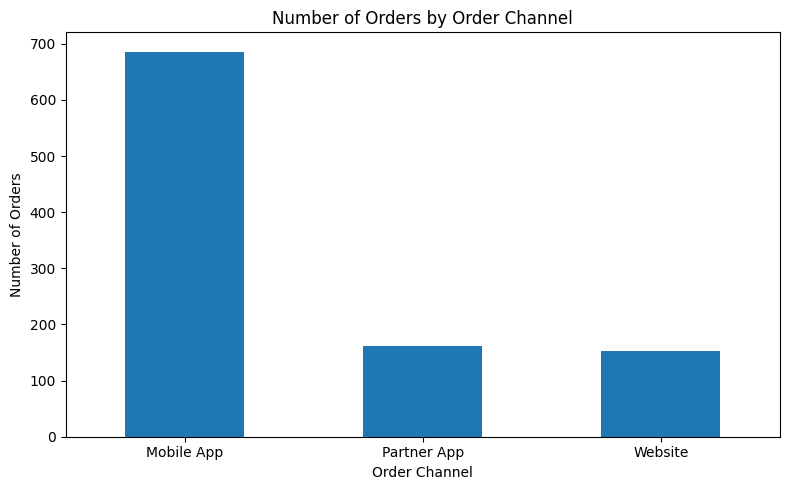

In [42]:
# Number of orders by Order Channel

channel_counts = work_df['Order Channel'].value_counts()

plt.figure(figsize=(8, 5))

channel_counts.plot(kind='bar')

plt.title('Number of Orders by Order Channel')
plt.xlabel('Order Channel')
plt.ylabel('Number of Orders')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Explaination**:The bar chart compares the number of orders across different ordering channels. Mobile App has the highest order count, indicating that it is the most frequently used platform.

**7.2 Number of Orders by Payment Method**

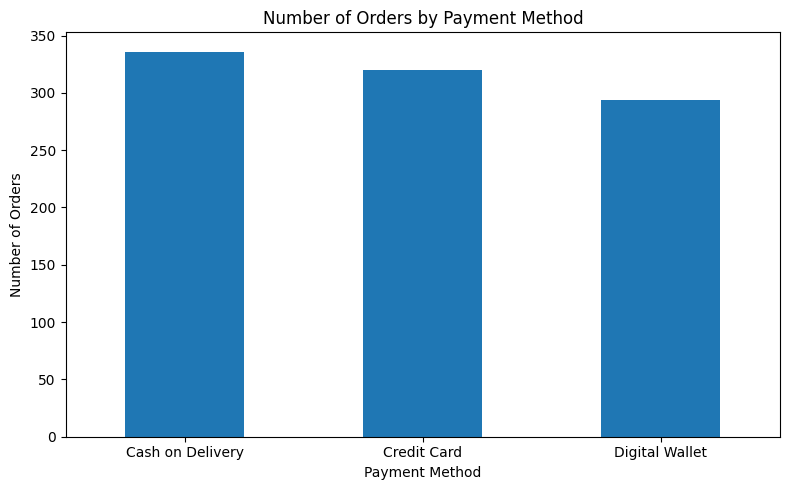

In [43]:
# Number of orders by Payment Method

payment_counts = (
    work_df[work_df['Payment Method'] != 'Unknown']
    ['Payment Method']
    .value_counts()
)

plt.figure(figsize=(8, 5))

payment_counts.plot(kind='bar')

plt.title('Number of Orders by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Orders')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Explaination**:The bar chart displays the distribution of orders across known payment methods. Cash on Delivery has the highest number of orders.


**7.3 Average Delivery Time by Weather Condition**


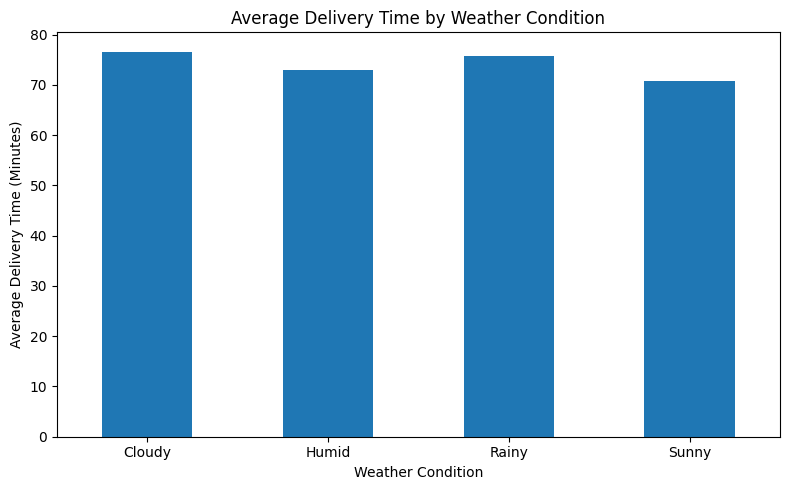

In [44]:
# Average delivery time by weather condition

weather_delivery = (
    work_df.groupby('Weather Condition')
    ['Delivery_Time_Minutes']
    .mean()
)

plt.figure(figsize=(8, 5))

weather_delivery.plot(kind='bar')

plt.title('Average Delivery Time by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Delivery Time (Minutes)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Explaination**:The bar chart compares average delivery duration across different weather conditions. It helps identify differences in delivery times under different weather conditions, without assuming that weather alone causes those differences.


**7.4 Daily Order Count**

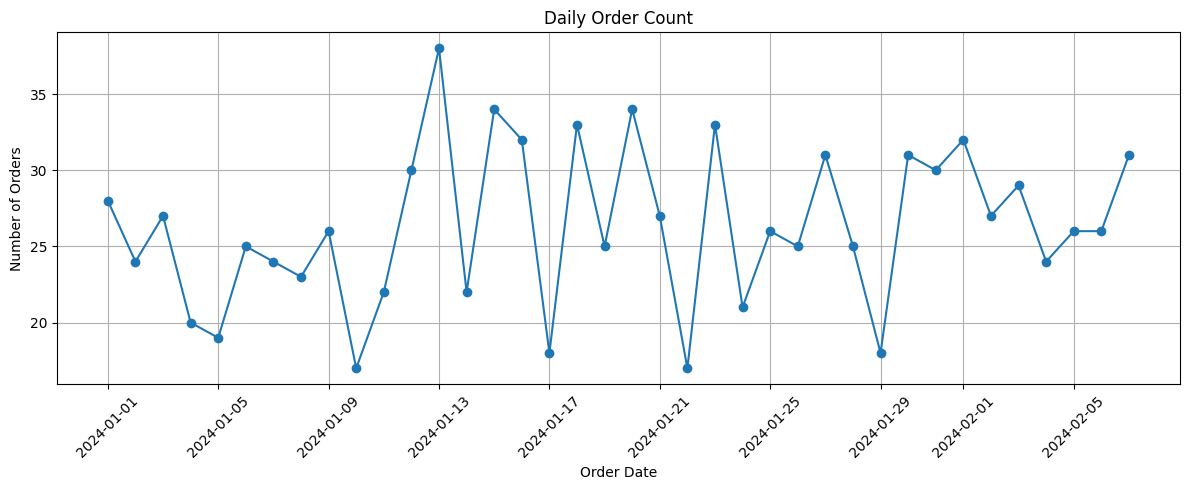

In [45]:
# Daily order count

daily_orders = (
    work_df.groupby('Order_Date')
    ['Order ID']
    .count()
)

plt.figure(figsize=(12, 5))

daily_orders.plot(kind='line', marker='o')

plt.title('Daily Order Count')
plt.xlabel('Order Date')
plt.ylabel('Number of Orders')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Explaination**:The line chart displays the number of orders placed on each date. It helps identify daily fluctuations and changes in order volume over the observed period.

### Task 7 — Visualization Observations

1. The order channel chart shows the distribution of orders across different ordering platforms.
2. The payment method chart identifies the commonly used payment methods.
3. The weather chart compares average delivery time across weather conditions.
4. The daily order chart illustrates changes in order volume over time.

These visualizations help understand ordering patterns and delivery
performance. They show associations and distributions, not necessarily
causal relationships.

### Task 8 — Data Validation

Validation is performed to ensure that the cleaned and transformed
dataset follows the documented cleaning rules and that the derived
columns are calculated correctly.

**8.1 Validate expected columns**

In [46]:
# Validate expected columns

expected_columns = [
    'Order ID',
    'Customer ID',
    'Restaurant ID',
    'Order Date and Time',
    'Delivery Date and Time',
    'Order Value',
    'Delivery Fee',
    'Payment Method',
    'Discounts and Offers',
    'Commission Fee',
    'Payment Processing Fee',
    'Refunds/Chargebacks',
    'Weather Condition',
    'Order Channel',
    'Delivery_Time_Minutes',
    'Order_Date',
    'Order_Hour',
    'Platform_Net_Revenue'
]

missing_columns = [
    col for col in expected_columns
    if col not in work_df.columns
]

print("Missing expected columns:", missing_columns)

print("All expected columns present:",
      len(missing_columns) == 0)

Missing expected columns: []
All expected columns present: True


**Explaination**:The transformed dataset is checked to ensure that all required original and derived columns are present. All expected columns are available.

**8.2 Validate data types**

In [47]:
# Check data types

print(work_df.dtypes)

print("\nDatetime validation:")

print(pd.api.types.is_datetime64_any_dtype(
    work_df['Order Date and Time']))

print(pd.api.types.is_datetime64_any_dtype(
    work_df['Delivery Date and Time']))

print("\nFinancial columns validation:")

for col in financial_columns:
    print(col, pd.api.types.is_numeric_dtype(work_df[col]))

Order ID                                int64
Customer ID                            object
Restaurant ID                          object
Order Date and Time            datetime64[ns]
Delivery Date and Time         datetime64[ns]
Order Value                           float64
Delivery Fee                          float64
Payment Method                         object
Discounts and Offers                   object
Commission Fee                        float64
Payment Processing Fee                float64
Refunds/Chargebacks                   float64
Weather Condition                      object
Order Channel                          object
Delivery Duration (Minutes)           float64
Delivery_Time_Minutes                 float64
Order_Date                             object
Order_Hour                              int32
Platform_Net_Revenue                  float64
dtype: object

Datetime validation:
True
True

Financial columns validation:
Order Value True
Delivery Fee True
Commission Fee

**Explaination**:Both order and delivery timestamps are in datetime format. All financial columns are numeric, allowing calculations and analysis to be performed correctly.

**8.3 Validate Delivery Durations**

In [48]:
# Check negative delivery durations

negative_delivery_records = work_df[
    work_df['Delivery_Time_Minutes'] < 0
]

print("Negative delivery durations:",
      len(negative_delivery_records))

print("Minimum delivery time:",
      work_df['Delivery_Time_Minutes'].min())

print("Maximum delivery time:",
      work_df['Delivery_Time_Minutes'].max())

Negative delivery durations: 0
Minimum delivery time: 30.0
Maximum delivery time: 119.0


**Explaination**:No negative delivery durations were found. The minimum delivery time is 30 minutes, and the maximum is 119 minutes. All 1,000 records have valid delivery durations.

**8.4 Manually Validate Calculations**

In [49]:
# Inspect a few records manually

sample_records = work_df[
    ['Order Date and Time',
     'Delivery Date and Time',
     'Delivery_Time_Minutes']
].head(5).copy()

sample_records['Manually_Calculated_Minutes'] = (
    sample_records['Delivery Date and Time'] -
    sample_records['Order Date and Time']
).dt.total_seconds() / 60

sample_records['Calculation_Matches'] = np.isclose(
    sample_records['Delivery_Time_Minutes'],
    sample_records['Manually_Calculated_Minutes']
)

display(sample_records)

,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes,Manually_Calculated_Minutes,Calculation_Matches
0,2024-02-01 01:11:52,2024-02-01 02:39:52,88.0,88.0,True
1,2024-02-02 22:11:04,2024-02-02 22:46:04,35.0,35.0,True
2,2024-01-31 05:54:35,2024-01-31 06:52:35,58.0,58.0,True
3,2024-01-16 22:52:49,2024-01-16 23:38:49,46.0,46.0,True
4,2024-01-29 01:19:30,2024-01-29 02:48:30,89.0,89.0,True


**Explaination**:The delivery-time calculations were manually checked against five sample records, and all results matched. The platform net revenue calculations were also checked against five sample records, and all results matched.

In [50]:
# Manually validate revenue calculation

revenue_sample = work_df.dropna(
    subset=[
        'Commission Fee',
        'Delivery Fee',
        'Payment Processing Fee',
        'Refunds/Chargebacks'
    ]
).head(5).copy()

revenue_sample['Manually_Calculated_Revenue'] = (
    revenue_sample['Commission Fee']
    + revenue_sample['Delivery Fee']
    - revenue_sample['Payment Processing Fee']
    - revenue_sample['Refunds/Chargebacks']
)

revenue_sample['Calculation_Matches'] = np.isclose(
    revenue_sample['Platform_Net_Revenue'],
    revenue_sample['Manually_Calculated_Revenue']
)

display(revenue_sample[
    ['Platform_Net_Revenue',
     'Manually_Calculated_Revenue',
     'Calculation_Matches']
])

,Platform_Net_Revenue,Manually_Calculated_Revenue,Calculation_Matches
0,103.0,103.0,True
1,215.0,215.0,True
2,180.0,180.0,True
5,-65.0,-65.0,True
6,112.0,112.0,True


In [51]:
# Compare missing values before and after cleaning

missing_comparison = pd.DataFrame({
    'Before Cleaning': raw_df.isnull().sum(),
    'After Cleaning': work_df.isnull().sum()
})

display(missing_comparison)

,Before Cleaning,After Cleaning
Commission Fee,40.0,40
Customer ID,0.0,0
Delivery Date and Time,0.0,0
Delivery Duration (Minutes),0.0,0
Delivery Fee,50.0,50
Delivery_Time_Minutes,NaN,0
Discounts and Offers,242.0,0
Order Channel,0.0,0
Order Date and Time,0.0,0
Order ID,0.0,0


In [52]:
# Count records excluded from important calculations

excluded_order_value = work_df['Order Value'].isna().sum()

excluded_delivery_time = work_df['Delivery_Time_Minutes'].isna().sum()

excluded_revenue = work_df['Platform_Net_Revenue'].isna().sum()

print("Records excluded from Order Value calculation:",
      excluded_order_value)

print("Records excluded from Delivery Time calculation:",
      excluded_delivery_time)

print("Records excluded from Revenue calculation:",
      excluded_revenue)

Records excluded from Order Value calculation: 40
Records excluded from Delivery Time calculation: 0
Records excluded from Revenue calculation: 172


In [53]:
# Generate final validation report

validation_report = {
    'Original Records': len(raw_df),

    'Cleaned Records': len(work_df),

    'Rows Removed': len(raw_df) - len(work_df),

    'Duplicate Rows Remaining': work_df.duplicated().sum(),

    'Repeated Order IDs': work_df['Order ID'].duplicated().sum(),

    'Missing Order Values': work_df['Order Value'].isna().sum(),

    'Invalid Delivery Durations': (
        work_df['Delivery_Time_Minutes'] < 0
    ).sum(),

    'Valid Delivery Records': (
        work_df['Delivery_Time_Minutes'].notna() &
        (work_df['Delivery_Time_Minutes'] >= 0)
    ).sum(),

    'Records with Valid Revenue': (
        work_df['Platform_Net_Revenue'].notna()
    ).sum()
}

validation_report_df = pd.DataFrame(
    list(validation_report.items()),
    columns=['Validation Metric', 'Result']
)

display(validation_report_df)

,Validation Metric,Result
0,Original Records,1010
1,Cleaned Records,1000
2,Rows Removed,10
3,Duplicate Rows Remaining,0
4,Repeated Order IDs,0
5,Missing Order Values,40
6,Invalid Delivery Durations,0
7,Valid Delivery Records,1000
8,Records with Valid Revenue,828


In [54]:
# Save the final cleaned and transformed dataset

work_df.to_csv(
    'food_orders_cleaned.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


### Task 8 — Final Validation Observations

The transformed dataset was validated for expected columns,
appropriate data types, duplicate records, delivery durations,
and platform net revenue calculations.

Manual verification was performed for delivery-time and
revenue calculations.

Missing financial values were retained according to the
documented business rules. Records with incomplete financial
components were excluded from the corresponding calculations.

The cleaned and transformed dataset was successfully saved
as food_orders_cleaned.csv.